In [6]:
#set working directory to project root
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print(project_root)

project_dir = Path("/Users/henristaehelin/Desktop/UZH/SDS320/project")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

images_dir = project_dir / "data/raw/imagery/sentinel2"
masks_dir = project_dir / "data/raw/raster"

print("Project:", project_dir)
print("Images exist:", images_dir.exists())
print("Masks exist:", masks_dir.exists())

/Users/henristaehelin/Desktop/UZH/SDS320/project
Project: /Users/henristaehelin/Desktop/UZH/SDS320/project
Images exist: True
Masks exist: True


# 1. Load Crop Data, Choose Scenes
We load data of crop field polygons and class types from Germany in 2023. In addition we choose scenes in which we will train, validate and test the model. 

#### a) Load Germany 2023 Data from the Eurocrops Dataset
Using the function "load_crop_fields" saved in a separate R script. It uses country code identifiers "nuts" to choose germany "dea", and ensures original names match the international crop label "hcat4_name".

In [7]:
from scripts.crop_field_loading import load_crop_fields

germany_2023 = load_crop_fields(
    vector_path=project_dir / "data/raw/vectors/dea_2023.parquet",
    lookup_path=project_dir / "data/raw/Eurocrops.csv",
    country_code="dea",
)

display(germany_2023.head())

,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,713879,575,7158611,0.1413,0.141340,"MULTIPOLYGON (((4075066.904 3118777.11, 407491...",dea,Blühfläche (AUM-Altmaßnahme,Flowering area (AUM-old measure),3310800000,flowers_ornamental_plants,0,No specified use
1,709592,66,7103747,0.0777,0.077780,"MULTIPOLYGON (((4061747.758 3135219.228, 40615...",dea,Kond.-Brache (aktive Begrünun,Fallow land (active greening),3311100000,fallow_land_not_crop,0,No specified use
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
3,713404,996,7131892,0.0639,0.064025,"MULTIPOLYGON (((4229259.343 3207621.8, 4229293...",dea,Unbefestigte Mieten AL,unfixed rents AL,3390000000,not_known_and_other,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use


We now have polygons and labels. We will use hcat4_name as this is the harmonized label across multiple countries.

Lets also see how many unique crops there are. 

In [11]:
#see number of unique crops
print(germany_2023["hcat4_name"].nunique())
print(germany_2023["hcat4_code"].nunique()) #making sure number of unique names and codes line up

173
173


#### b) Choose subset of crop types and set crop ids
Instead lets choose the 30 most common crop types. Upon inspection of the crop types there are some which might be unsuitable for a model because they are ambiguous/miscellaneous and have no clear type or consistent spectral info which the model could learn. 

In [13]:
# Exclude unsuitable or ambiguous crop categories
excluded_crops = [
    "fallow_land_not_crop",
    "not_known_and_other",
    "unmaintained",
    "seed_seedlings",
    "nurseries_nursery",
    "poaceae_grasses",
    "other_flowers_ornamental_plants",
    "flowers_ornamental_plants",
    "other_aromatic_medicinal_culinary_plants_spices_herbs",
    "afforestation_reforestation",
    "spring_mixed_grains",
    "other_industrial_crops",
    "other_poaceae_grasses",
    "other_arable_land_crops",
]

crop_counts = (
    germany_2023.loc[
        ~germany_2023["hcat4_name"].isin(excluded_crops),
        "hcat4_name"
    ]
    .value_counts()
)

subset = crop_counts.head(30).index.tolist()

display(crop_counts.head(30))

hcat4_name
permanent_grassland         294894
maize_corn_popcorn           91195
winter_common_soft_wheat     69959
winter_barley                43410
temporary_grassland          28327
winter_triticale             17376
winter_rapeseed_rape         16689
winter_rye                   15277
sugar_beet                   13079
potatoes                     11308
orchards_fruits               9073
clover                        5298
spring_barley                 3529
spring_oats                   3289
beans                         3072
peas                          2117
asparagus                     1672
alfalfa_lucerne               1506
strawberries                  1452
spring_common_soft_wheat      1320
cereal                        1171
fresh_vegetables              1011
onions                         915
pumpkin_squash_gourd           903
conifers                       903
brassicaceae_cruciferae        881
carrots_daucus                 868
winter_spelt                   808
miscanthu

In [27]:
# Keep only the 30 selected crop types
reduced_crops = germany_2023[
    germany_2023["hcat4_name"].isin(subset)
].copy()

print("Original polygons:", len(germany_2023))
print("Subset polygons:", len(reduced_crops))
print("% Polygons kept:", round(len(reduced_crops)/(len(germany_2023))*100))
print("Crop types present:", reduced_crops["hcat4_name"].nunique())

reduced_crops.head(5)

Original polygons: 748208
Subset polygons: 642867
% Polygons kept: 86
Crop types present: 30


,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
2,711311,994,7060421,0.0053,0.005314,"MULTIPOLYGON (((4242608.123 3250820.547, 42426...",dea,Unbefestigte Mieten DGL,Unfixed rents permanent grass land,3320100000,permanent_grassland,0,No specified use
4,713622,860,7135902,2.8559,2.857417,"MULTIPOLYGON (((4142676.982 3210526.616, 41427...",dea,Spargel,asparagus,3310706000,asparagus,0,No specified use
6,714367,602,7209215,0.6296,0.629910,"MULTIPOLYGON (((4115046.183 3117774.226, 41151...",dea,Kartoffeln,potatoes,3310300000,potatoes,0,No specified use
9,716260,115,7061460,2.4301,2.432082,"MULTIPOLYGON (((4243063.131 3249725.238, 42432...",dea,Winterweichweizen,Winter soft wheat,3310101001,winter_common_soft_wheat,0,No specified use
10,716676,633,7282261,0.1645,0.164611,"MULTIPOLYGON (((4085257.054 3150768.223, 40852...",dea,Zwiebeln/Lauch,Onions / leeks,3310708040,onions,0,No specified use


In [15]:
# Define consistent crop IDs before selecting areas
crop_mapping = {
    name: i + 1
    for i, name in enumerate(
        sorted(reduced_crops["hcat4_name"].dropna().unique())
    )
}

assert len(crop_mapping) == 30
print(crop_mapping)

{'alfalfa_lucerne': 1, 'asparagus': 2, 'beans': 3, 'berries_berry_species': 4, 'brassicaceae_cruciferae': 5, 'carrots_daucus': 6, 'cereal': 7, 'clover': 8, 'conifers': 9, 'fresh_vegetables': 10, 'maize_corn_popcorn': 11, 'miscanthus_silvergrass': 12, 'onions': 13, 'orchards_fruits': 14, 'peas': 15, 'permanent_grassland': 16, 'potatoes': 17, 'pumpkin_squash_gourd': 18, 'spring_barley': 19, 'spring_common_soft_wheat': 20, 'spring_oats': 21, 'strawberries': 22, 'sugar_beet': 23, 'temporary_grassland': 24, 'winter_barley': 25, 'winter_common_soft_wheat': 26, 'winter_rapeseed_rape': 27, 'winter_rye': 28, 'winter_spelt': 29, 'winter_triticale': 30}


#### c) Choose Scenes
We will choose scenes for where our model will train, validate and test, in a 70/15/15 split. Ideally we choose scenes that have an even spread of crop types present and all 30 crop types we selected are represented. 

Lets choose 50 of them, and set a 10km minimum distance between area boundaries to avoid areas being too similar. Also lets prioritize rare crop types and ensure that there is an even crop spread and all 30 crop types are represented. We have a candidate score which is based on crop distribution within the areas, with higher numbers being more diverse. The code below runs on functions in a python script. This allows us to easily change the number of areas and area size in (m^2)

Selected areas: 50


,area_id,grid_id,n_crop_types,n_fields,score,geometry
0,1,729,28,660,48.122110,"POLYGON ((358400 5621760, 358400 5626880, 3532..."
1,2,822,25,838,21.527579,"POLYGON ((368640 5606400, 368640 5611520, 3635..."
2,3,261,22,596,15.915255,"POLYGON ((307200 5683200, 307200 5688320, 3020..."
3,4,498,23,575,12.091104,"POLYGON ((332800 5667840, 332800 5672960, 3276..."
4,5,2043,21,783,10.410864,"POLYGON ((496640 5713920, 496640 5719040, 4915..."


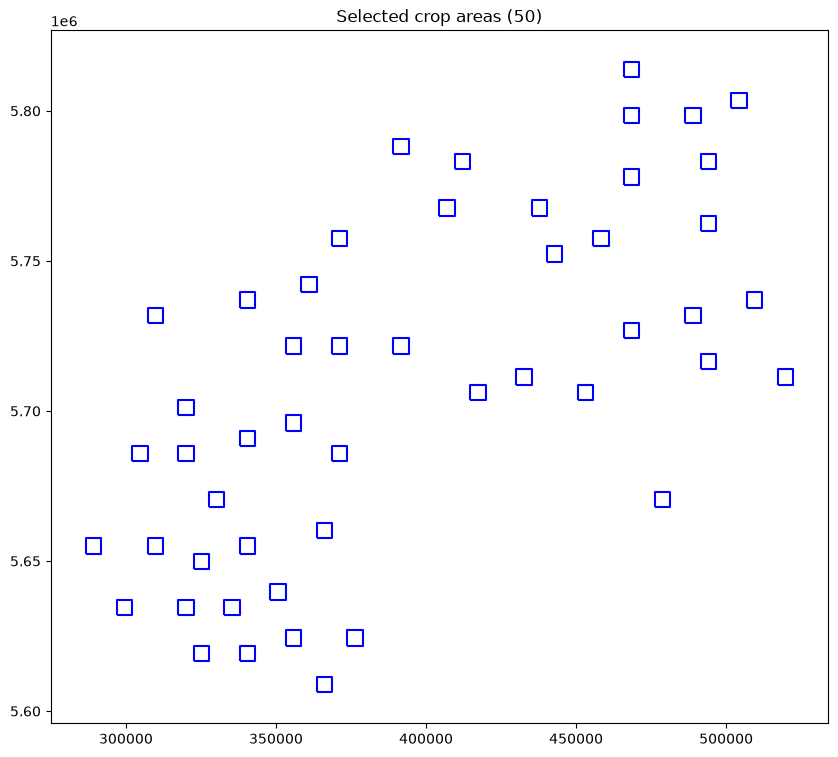

In [41]:
from scripts.crop_area_selection import select_crop_areas, plot_crop_areas
import matplotlib.pyplot as plt

selected_areas = select_crop_areas(
    crop_fields=reduced_crops,
    area_size=5120, #this number is useful for creating strides later
    n_areas=50,
    min_distance=10000,
    min_crop_types=10,
)

print(f"Selected areas: {len(selected_areas)}")

display(selected_areas.head())

fig, ax = plot_crop_areas(selected_areas)
plt.show()